
# ILLM Lab 4 — N-gram Language Models & Smoothing on IndicCorpV2

Builds **unigram, bigram, trigram, and quadrigram** ($N=1,2,3,4$) language models on
the **same Hindi corpus and the same train/dev/test split** used in the previous
BPE/WordPiece lab, under **five** probability-estimation settings, and compares them
by **perplexity** on held-out data:

1. Unsmoothed (raw MLE counts)
2. Add-1 (Laplace) smoothing
3. Add-$k$ smoothing ($0<k<1$, chosen by grid search)
4. Interpolated (Jelinek–Mercer) smoothing
5. Kneser–Ney smoothing ($d=0.75$)

Everything is implemented from scratch (no `nltk.lm`, no `kenlm`), so that every
formula in the assignment is visible as actual, readable code.

---

## 1. Deep analysis of the assignment

| # | Requirement | What it means concretely |
|---|---|---|
| 1 | "Use the same corpus... same training, development, and test splits" as the previous assignment | Reload the exact same `train_pool` / `dev_sentences` / `test_sentences` produced by Lab 3 (Sections 3–4 there), instead of re-downloading or re-splitting — otherwise "same split" wouldn't actually be true. |
| 2 | Build $N=1,2,3,4$ models | A unigram model has no context; bigram conditions on 1 previous word; trigram on 2; quadrigram on 3. All four share the *same underlying counts* — only how those counts are turned into probabilities differs. |
| 3 | Unsmoothed | Plain MLE: $P(w_i\mid \text{context}) = C(\text{context},w_i)/C(\text{context})$. Assigns **zero** probability to any unseen n-gram — deliberately included so its failure mode (infinite perplexity on real held-out text) is visible and discussed, not hidden. |
| 4 | Add-1 / Add-$k$ | Uniform pseudo-count smoothing; add-1 is the special case $k=1$. |
| 5 | Interpolated, with a given unigram formula ($\lambda$, $V$) | The prompt gives the **base case** explicitly (mix the unigram MLE with a uniform distribution over the vocabulary). For $N=2,3,4$ we use the standard generalization of that same idea — recursively mix each order's MLE with the *already-interpolated* lower-order model (Jelinek–Mercer interpolation) — since that is the natural, standard extension of exactly the formula given. |
| 6 | Kneser–Ney, $d=0.75$ | Absolute discounting plus a **continuation-probability** backoff, so a word's lower-order weight reflects *how many distinct contexts it appears in*, not its raw frequency (this is what makes KN handle rare/novel contexts so much better than Laplace-style smoothing). |
| 7 | Compare perplexities | Report dev *and* test perplexity for all $5\times4=20$ (method, order) combinations in one table, and discuss the trends. |

**Design decisions (stated explicitly, since the assignment doesn't specify these):**

- **Tokenization:** plain whitespace splitting (`text.split()`), lowercased. This
  matches how sentence length was already measured in Lab 3 (`len(s.split())`), and
  keeps this lab's scope on *smoothing*, not on the punctuation-tokenization question
  already explored (and fixed) in Lab 3.
- **Closed vocabulary / `<UNK>`:** any training word type occurring **only once**
  (a singleton) is collapsed to `<UNK>` before counting; any dev/test word never seen
  in that reduced training vocabulary also maps to `<UNK>`. Without this, the model
  would crash (division by zero / undefined probability) on the first novel word in
  dev/test — this is standard practice for n-gram LMs (Jurafsky & Martin, *Speech and
  Language Processing*, Ch. 3), not something the raw assignment text mentions but
  something every real implementation needs.
- **Sentence boundaries:** each sentence is padded with $(N-1)$ `<s>` tokens at the
  start and one `</s>` at the end, *per order* — e.g. a quadrigram model sees 3
  `<s>` tokens before the first real word. `<s>` is a context-only symbol: it is
  **excluded** from the vocabulary $V$ used in Laplace/Add-$k$'s denominator, since
  the model is never asked to *generate* `<s>`.
- **Add-$k$'s $k$ and the interpolation $\lambda$'s** are not given by the
  assignment (beyond "$0<k<1$"), so both are **tuned on the dev set** by grid search
  and reported with justification, then evaluated on test — standard train/dev/test
  discipline, and consistent with how Lab 3 tuned its own design choices.
- **Counts are built once, reused everywhere:** all 5 smoothing methods for a given
  order read from the *same* underlying count tables — smoothing is just a different
  arithmetic recipe applied to the same raw evidence, which is also why 20
  combinations don't require 20 separate training passes.

## 2. Plan for this notebook

```
Reload train/dev/test sentences from Lab 3 (no re-download, no re-split)
        ▼
Tokenize (lowercase + whitespace split) -> build a closed vocabulary with <UNK>
        ▼
Count n-grams for N=1..4 on TRAIN ONLY (raw counts + context counts)
        ▼
Build Kneser-Ney's continuation-count tables (derived from the same raw counts)
        ▼
Toy-corpus sanity checks: every smoothed distribution must sum to 1 over the
        vocabulary, and must actually depend on its context (not silently
        collapse to the unigram distribution) -- both checked before scaling up
        ▼
Tune Add-k's k and the interpolation lambdas on DEV perplexity
        ▼
Compute dev + test perplexity for all 5 methods x 4 orders (20 combinations)
        ▼
Compare, plot, and discuss
```



## Section 1 — Environment Setup

Reuses the same `LANGUAGE_CODE` and `RANDOM_SEED` as Lab 3, so filenames match up
automatically.


In [1]:

import os
import re
import math
import pickle
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

LANGUAGE_CODE = "hin_Deva"   # must match the value used in the Lab 3 notebook
MAX_ORDER = 4                 # quadrigram is the highest order requested
DEV_SIZE = 1000
TEST_SIZE = 1000

print("Environment ready.")


Environment ready.



## Section 2 — Reload the SAME Corpus & Splits from Lab 3

Lab 3 already produced (and saved to disk in the same working directory):

- `{LANGUAGE_CODE}_sentences.csv` — every unique sentence collected from the corpus
  (Lab 3, Section 3).
- `{LANGUAGE_CODE}_tokenizer_results.pkl` — a pickle containing the exact
  `dev_sentences` and `test_sentences` that Lab 3's length-stratified split produced
  (Lab 3, Section 13).

Reloading these two files — rather than re-running the stratified-split code — is
the most airtight way to guarantee **byte-identical** splits: the train set is then
simply defined as *everything in the full corpus that is not dev and not test*,
using the actual dev/test sentences that were used before, not a freshly re-derived
approximation of them.

> **If you see a `FileNotFoundError` here:** run the Lab 3 notebook first (through
> at least Section 13), in the same folder as this notebook, so these two files
> exist on disk.


In [2]:

CSV_PATH = f"/Users/akshdharodiya/Desktop/SEM_7_LAB_PRACTICALS/LLM_LAB/LLM_LAB_3_13_08_26/hin_Deva_sentences.csv"
PKL_PATH = f"/Users/akshdharodiya/Desktop/SEM_7_LAB_PRACTICALS/LLM_LAB/LLM_LAB_3_13_08_26/hin_Deva_tokenizer_results.pkl"

for path in (CSV_PATH, PKL_PATH):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing '{path}'. Run the Lab 3 (BPE/WordPiece) notebook first, in this "
            f"same working directory, so the corpus + splits it saved are available here."
        )

all_sentences = pd.read_csv(CSV_PATH, encoding="utf-8")["text"].tolist()

with open(PKL_PATH, "rb") as f:
    prev_results = pickle.load(f)
dev_sentences_raw = prev_results["dev_sentences"]
test_sentences_raw = prev_results["test_sentences"]

# train = everything else. Using set membership against the ACTUAL loaded dev/test
# sentences (rather than re-deriving them) guarantees no overlap and no drift from
# whatever Lab 3 actually produced.
_dev_set = set(dev_sentences_raw)
_test_set = set(test_sentences_raw)
train_sentences_raw = [s for s in all_sentences if s not in _dev_set and s not in _test_set]

print(f"Reloaded from Lab 3:")
print(f"  Full corpus : {len(all_sentences):,} sentences")
print(f"  Train       : {len(train_sentences_raw):,} sentences")
print(f"  Dev         : {len(dev_sentences_raw):,} sentences")
print(f"  Test        : {len(test_sentences_raw):,} sentences")
assert len(dev_sentences_raw) == DEV_SIZE and len(test_sentences_raw) == TEST_SIZE


Reloaded from Lab 3:
  Full corpus : 1,002,000 sentences
  Train       : 1,000,000 sentences
  Dev         : 1,000 sentences
  Test        : 1,000 sentences



## Section 3 — Tokenization

Plain whitespace splitting, lowercased (see the design-decision note in Section 1
above for why). This is applied to train, dev, and test identically.


In [3]:

def word_tokenize(sentence):
    return sentence.lower().split()

train_tokenized = [word_tokenize(s) for s in train_sentences_raw]
dev_tokenized = [word_tokenize(s) for s in dev_sentences_raw]
test_tokenized = [word_tokenize(s) for s in test_sentences_raw]

print("Example tokenized train sentence:")
print(train_tokenized[0])


Example tokenized train sentence:
['लोगों', 'को', 'बिलों', 'संबंधी', 'सुविधा', 'देना', 'ही', 'उनका', 'काम']



## Section 4 — Closed Vocabulary & `<UNK>` Handling

A word type that appears only **once** in the entire training set is replaced with
the special token `<UNK>` — everywhere it occurs, including in the sentence(s) it
came from. This does two things at once:

1. It caps vocabulary size at a manageable level (long-tail singleton words in a
   1,000,000-sentence corpus can otherwise number in the hundreds of thousands).
2. Crucially, it gives `<UNK>` **enough training examples to have its own
   meaningful probability**, so that when dev/test contains a word never seen in
   training at all, the model maps it to `<UNK>` too and still produces a valid,
   non-zero, non-crashing probability for it — instead of the model just failing.

$V$ (the vocabulary size used throughout Section 7's smoothing formulas) is the
number of **distinct word types the model can generate**: every kept training word,
plus `<UNK>` itself, plus `</s>`. `<s>` is deliberately **excluded** — it is a
context-only padding symbol; the model is never scored on producing it.


In [4]:

BOS, EOS, UNK = "<s>", "</s>", "<UNK>"
MIN_COUNT = 2   # word types with training count < MIN_COUNT collapse to <UNK>

def build_vocab(train_sents, min_count=MIN_COUNT):
    word_counts = Counter(w for s in train_sents for w in s)
    vocab = {w for w, c in word_counts.items() if c >= min_count}
    vocab.add(UNK)
    vocab.add(EOS)
    return vocab, word_counts

def replace_unk(sentence, vocab):
    return [w if w in vocab else UNK for w in sentence]

vocab, train_word_counts = build_vocab(train_tokenized)
V = len(vocab)

train_sents = [replace_unk(s, vocab) for s in train_tokenized]
dev_sents = [replace_unk(s, vocab) for s in dev_tokenized]
test_sents = [replace_unk(s, vocab) for s in test_tokenized]

n_raw_types = len(train_word_counts)
n_singletons = sum(1 for c in train_word_counts.values() if c == 1)
print(f"Raw training word types : {n_raw_types:,}")
print(f"Singletons -> <UNK>     : {n_singletons:,} ({n_singletons/n_raw_types:.1%} of types)")
print(f"Final vocabulary size V : {V:,}")


Raw training word types : 455,695
Singletons -> <UNK>     : 283,099 (62.1% of types)
Final vocabulary size V : 172,598



## Section 5 — N-gram Counting

For an order-$n$ model, every sentence is padded with $(n-1)$ `<s>` tokens at the
start and one `</s>` at the end, then every contiguous window of $n$ tokens is
counted:

$$C(w_{i-n+1}^{\,i}) = \text{number of times the exact sequence } w_{i-n+1},\dots,w_i \text{ appears in training}$$

Two tables are built for **every** order $n=1,\dots,4$, from the training set only:

- `ngram_counts[n]` — a dict from an $n$-tuple to its raw count $C(w_{i-n+1}^{\,i})$.
- `context_counts[n]` — a dict from an $(n-1)$-tuple (the *context*) to
  $C(w_{i-n+1}^{\,i-1}) = \sum_{w} C(w_{i-n+1}^{\,i-1}, w)$, i.e. how many times that
  context occurred, needed as the denominator of every MLE-based formula below.
  For $n=1$ the context is the empty tuple, and `context_counts[1][()]` is just the
  total number of training tokens.

Both tables for all four orders are built in a **single pass** over the training
data, since every smoothing method in Section 7 reads from these same tables —
counting is done once, not once per smoothing method.


In [5]:

def pad(sentence, n):
    """(n-1) <s> tokens at the start, one </s> at the end."""
    return [BOS] * (n - 1) + sentence + [EOS]

def count_ngrams(sentences, max_order):
    ngram_counts = {n: Counter() for n in range(1, max_order + 1)}
    context_counts = {n: Counter() for n in range(1, max_order + 1)}
    for s in sentences:
        for n in range(1, max_order + 1):
            toks = pad(s, n)
            for i in range(n - 1, len(toks)):
                ngram = tuple(toks[i - n + 1: i + 1])
                ngram_counts[n][ngram] += 1
                context_counts[n][ngram[:-1]] += 1
    return ngram_counts, context_counts

print("Counting n-grams for orders 1-4 on the full training set...")
print("(this is the most expensive cell in the notebook -- expect a few minutes on 1,000,000 sentences)")
ngram_counts, context_counts = count_ngrams(train_sents, MAX_ORDER)

total_unigrams = context_counts[1][()]
for n in range(1, MAX_ORDER + 1):
    print(f"  order {n}: {len(ngram_counts[n]):,} distinct n-grams")
print(f"Total training tokens (unigram denominator): {total_unigrams:,}")


Counting n-grams for orders 1-4 on the full training set...
(this is the most expensive cell in the notebook -- expect a few minutes on 1,000,000 sentences)
  order 1: 172,598 distinct n-grams
  order 2: 3,425,113 distinct n-grams
  order 3: 9,511,401 distinct n-grams
  order 4: 13,830,732 distinct n-grams
Total training tokens (unigram denominator): 18,995,974



## Section 6 — Kneser-Ney: Continuation-Count Tables

Kneser-Ney's key idea: at every order **below** the top order, a word's weight
shouldn't come from *how often* it occurs, but from *how many distinct contexts it
occurs in* — its **continuation count**:

$$N_{1+}(\bullet\, x) = \big|\{\,w' : C(w', x) > 0\,\}\big|$$

i.e. the number of distinct single-word left-extensions of the sequence $x$, found
by looking at the *next order up*. (Classic example: "Francisco" is very frequent in
English text, but almost always right after "San" — so it should get a *low*
continuation-based unigram weight despite its high raw frequency, since it
continues almost no other context. Raw-frequency-based smoothing like Laplace can't
represent this; Kneser-Ney is specifically built to.)

Four tables are precomputed once, for every order $n=1,\dots,\text{MAX\_ORDER}-1$
(the top order uses the raw tables from Section 5 directly instead — see Section 7):

| Table | Definition | Used for |
|---|---|---|
| `cont_count[n][x]` | $N_{1+}(\bullet\,x)$ for an $n$-length sequence $x$ | the discounted numerator at order $n$ |
| `cont_denom[n][ctx]` | $\sum_{w} N_{1+}(\bullet\,\text{ctx},w)$ | the discounted denominator at order $n$ |
| `cont_distinct_next[n][ctx]` | $\big|\{w : N_{1+}(\bullet\,\text{ctx},w)>0\}\big|$ | $\lambda(\text{ctx})$'s numerator at order $n$ |
| `raw_distinct_next[n][ctx]` | $\big|\{w : C(\text{ctx},w)>0\}\big|$ | $\lambda(\text{ctx})$'s numerator **at the top order only** (which uses raw counts throughout, not continuation counts) |

All four are derived purely from the *key sets* of the count tables already built in
Section 5 (presence, not frequency) — no second pass over the raw training text is
needed.


In [6]:

def build_continuation_tables(ngram_counts, max_order):
    # N_1+(* x) for every x of length n < max_order, from the (n+1)-gram table's keys
    cont_count = {n: Counter() for n in range(1, max_order)}
    for n in range(1, max_order):
        for ngram in ngram_counts[n + 1].keys():
            cont_count[n][ngram[1:]] += 1   # drop the leftmost word

    # aggregate cont_count up to the (n-1)-length context level, for the denominator
    # and for lambda's numerator at every order below the top
    cont_denom = {n: Counter() for n in range(1, max_order)}
    cont_distinct_next = {n: Counter() for n in range(1, max_order)}
    for n in range(1, max_order):
        for ngram, c in cont_count[n].items():
            ctx = ngram[:-1]
            cont_denom[n][ctx] += c
            cont_distinct_next[n][ctx] += 1

    # lambda's numerator at the TOP order uses raw counts, not continuation counts
    raw_distinct_next = {n: Counter() for n in range(1, max_order + 1)}
    for n in range(1, max_order + 1):
        for ngram in ngram_counts[n].keys():
            raw_distinct_next[n][ngram[:-1]] += 1

    return cont_count, cont_denom, cont_distinct_next, raw_distinct_next

print("Building Kneser-Ney continuation tables...")
cont_count, cont_denom, cont_distinct_next, raw_distinct_next = build_continuation_tables(ngram_counts, MAX_ORDER)
print("Done.")
print(f"Total distinct bigram types N_1+(*,*) = {sum(cont_count[1].values()):,}  (unigram continuation-probability denominator)")


Building Kneser-Ney continuation tables...
Done.
Total distinct bigram types N_1+(*,*) = 3,425,113  (unigram continuation-probability denominator)



## Section 7 — The Five Smoothing Formulas

All five functions below take an $n$-tuple `ngram` (its last element is the target
word $w_i$, the first $n-1$ elements are the context) and return
$P(w_i \mid \text{context})$. They all read from the **same** `ngram_counts` /
`context_counts` tables built once in Section 5 (and, for Kneser-Ney, the tables
from Section 6) — smoothing is just a different way of turning the same evidence
into a probability.

### 7.1 Unsmoothed (Maximum Likelihood Estimate)

$$P_{MLE}(w_i \mid w_{i-n+1}^{\,i-1}) = \frac{C(w_{i-n+1}^{\,i})}{C(w_{i-n+1}^{\,i-1})}$$

If the context was never seen in training, this is undefined — treated as
probability $0$. **This is deliberately kept "broken" this way**: it is what
motivates every other method in this section, and its failure (infinite perplexity
on real held-out text) is one of the results we want to actually see in Section 11,
not paper over.

### 7.2 / 7.3 Add-1 (Laplace) / Add-$k$ Smoothing

$$P_{Add\text{-}k}(w_i \mid c) = \frac{C(c, w_i) + k}{C(c) + kV}, \qquad 0 < k \le 1$$

Add-1 is the special case $k=1$. Adding $k$ to every possible $(c, w)$ pair (there
are $V$ of them for a fixed context $c$) and $kV$ to the denominator keeps this a
valid probability distribution for **any** context, seen or not — even a context
with $C(c)=0$ still gets a well-defined uniform distribution ($k/kV = 1/V$ per word).

### 7.4 Interpolated (Jelinek–Mercer) Smoothing

Recursively mixes each order's own MLE with the **already-smoothed** lower-order
model, top-down:

$$P_{interp}^{(n)}(w_i \mid w_{i-n+1}^{\,i-1}) = \lambda_n\, P_{MLE}^{(n)}(w_i \mid w_{i-n+1}^{\,i-1}) \;+\; (1-\lambda_n)\, P_{interp}^{(n-1)}(w_i \mid w_{i-n+2}^{\,i-1})$$

with $\lambda_n \in (0,1)$ a tunable weight per order (tuned on dev — Section 10).
The recursion bottoms out at $n=1$ using **exactly the formula given in the
assignment** — the unigram MLE mixed with a uniform distribution over the
vocabulary:

$$P_{interp}^{(1)}(w_i) = \lambda \cdot \frac{C(w_i)}{N} + (1-\lambda)\cdot \frac{1}{V}$$

where $N$ is the total number of training tokens. (One subtlety, caught by the
Section 9 sanity checks below: if a *higher*-order context was never seen in
training at all, $P_{MLE}^{(n)}$ is undefined for every word, so *all* weight must
go to the lower order for that specific context — using the fixed $\lambda_n$
anyway would silently throw away $(1-\lambda_n)$ worth of probability mass and
break normalization.)

### 7.5 Kneser–Ney Smoothing ($d=0.75$)

At the **top** order ($n=\text{MAX\_ORDER}$), absolute discounting subtracts a fixed
discount $d$ from every nonzero count and redistributes it via a backoff weight
$\lambda(\text{context})$:

$$P_{KN}^{(n)}(w_i \mid c) = \frac{\max\big(C(c,w_i)-d,\,0\big)}{C(c)} \;+\; \lambda(c)\, P_{KN}^{(n-1)}(w_i \mid c')$$

$$\lambda(c) = \frac{d \cdot \big|\{w : C(c,w)>0\}\big|}{C(c)}$$

where $c'$ drops the earliest word of $c$. At every order **below** the top, every
raw count above is replaced with the corresponding **continuation count** from
Section 6 (both the discounted numerator *and* $\lambda$'s numerator/denominator
switch together) — that substitution is the entire definition of Kneser-Ney. The
recursion bottoms out at a pure continuation probability:

$$P_{KN}^{(1)}(w) = \frac{N_{1+}(\bullet\,w)}{N_{1+}(\bullet\,\bullet)}$$



In [7]:

# ---- 7.1 Unsmoothed -----------------------------------------------------------
def p_unsmoothed(ngram, n, ngram_counts, context_counts):
    ctx = ngram[:-1]
    ctx_c = context_counts[n][ctx]
    if ctx_c == 0:
        return 0.0
    return ngram_counts[n][ngram] / ctx_c


# ---- 7.2 / 7.3 Add-1 / Add-k ---------------------------------------------------
def p_add_k(ngram, n, ngram_counts, context_counts, V, k=1.0):
    ctx = ngram[:-1]
    ctx_c = context_counts[n][ctx]
    return (ngram_counts[n][ngram] + k) / (ctx_c + k * V)


# ---- 7.4 Interpolated (Jelinek-Mercer) ----------------------------------------
def p_interpolated(ngram, n, ngram_counts, context_counts, lambdas, V, total_unigrams):
    if n == 1:
        w = ngram[-1]
        lam1 = lambdas[1]
        mle = ngram_counts[1][(w,)] / total_unigrams
        return lam1 * mle + (1 - lam1) * (1.0 / V)

    ctx = ngram[:-1]
    ctx_c = context_counts[n][ctx]
    lower = p_interpolated(ngram[1:], n - 1, ngram_counts, context_counts, lambdas, V, total_unigrams)
    if ctx_c == 0:
        # Context never seen in training at this order: no valid MLE_n term exists,
        # so ALL weight goes to the lower order (else normalization breaks -- see
        # the Section 9 sanity check).
        return lower
    mle_n = ngram_counts[n][ngram] / ctx_c
    lam_n = lambdas[n]
    return lam_n * mle_n + (1 - lam_n) * lower


# ---- 7.5 Kneser-Ney -------------------------------------------------------------
def p_kneser_ney(ngram, n, ngram_counts, context_counts, cont_count, cont_denom,
                  cont_distinct_next, raw_distinct_next, max_order, d=0.75):
    if n == 1:
        w = ngram[-1]
        num = cont_count[1][(w,)]
        denom = sum(cont_count[1].values())
        if denom == 0:
            return 1.0 / max(1, len(raw_distinct_next[1]) or 1)
        return num / denom

    ctx = ngram[:-1]
    is_top = (n == max_order)
    if is_top:
        c_ctx_w = ngram_counts[n][ngram]
        c_ctx = context_counts[n][ctx]
        n_distinct_after_ctx = raw_distinct_next[n][ctx]
    else:
        c_ctx_w = cont_count[n][ngram]
        c_ctx = cont_denom[n][ctx]
        n_distinct_after_ctx = cont_distinct_next[n][ctx]

    lower = p_kneser_ney(ngram[1:], n - 1, ngram_counts, context_counts,
                          cont_count, cont_denom, cont_distinct_next,
                          raw_distinct_next, max_order, d)

    if c_ctx == 0:
        return lower  # context never seen at this order -> full fallback

    discounted = max(c_ctx_w - d, 0) / c_ctx
    lam_ctx = (d * n_distinct_after_ctx) / c_ctx
    return discounted + lam_ctx * lower

print("All five probability functions defined.")


All five probability functions defined.



## Section 8 — Perplexity

For a held-out set of sentences with $M$ total scored tokens (every real word plus
each sentence's `</s>`, but **not** the `<s>` padding, since the model is never
scored on producing padding), perplexity is:

$$PP = \exp\left(-\frac{1}{M}\sum_{i=1}^{M} \log P\big(w_i \mid w_{i-n+1}^{\,i-1}\big)\right)$$

Lower perplexity = the model assigned higher probability to the actual held-out
text = a better fit. If **any** single token gets probability $0$ (only possible
under the unsmoothed model), the sum becomes $-\infty$ and perplexity is reported as
`inf` — this is not a bug, it's the correct mathematical consequence of a zero
probability, and precisely the failure mode Section 11 discusses.


In [8]:

def perplexity(sentences, n, prob_fn):
    log_prob_sum = 0.0
    token_count = 0
    for s in sentences:
        toks = pad(s, n)
        for i in range(n - 1, len(toks)):
            ngram = tuple(toks[i - n + 1: i + 1])
            p = prob_fn(ngram)
            if p <= 0:
                return float("inf")
            log_prob_sum += math.log(p)
            token_count += 1
    return math.exp(-log_prob_sum / token_count)

print("perplexity() defined.")


perplexity() defined.



## Section 9 — Toy-Corpus Sanity Checks (before running at scale)

Same philosophy as Lab 3: validate the algorithms on a small, inspectable corpus
*before* trusting them on a million real sentences. Two checks matter here, and both
caught real bugs during development of this notebook:

1. **Normalization** — for a fixed context, $\sum_{w \in V} P(w \mid \text{context})$
   must equal $1$ for every smoothed method (unsmoothed is exempt for contexts never
   seen in training, where it's correctly all-zero).
2. **Context sensitivity** — a *much* sneakier failure mode: a bug that silently
   makes every context fall back to the same lower-order distribution will *still*
   pass check #1 (it sums to 1 just fine) while being **completely wrong**, since it
   no longer actually depends on context. So the distribution over the next word is
   also checked to be genuinely different for different contexts, and to
   qualitatively make sense given the toy corpus's actual bigrams.


In [9]:

toy_sentences = [
    "the cat sat on the mat".split(),
    "the dog sat on the log".split(),
    "the cat chased the dog".split(),
    "a cat and a dog are friends".split(),
    "the dog barked at the cat".split(),
    "a dog sat on a mat".split(),
]

toy_vocab, _ = build_vocab(toy_sentences, min_count=1)  # keep every toy word
toy_train = [replace_unk(s, toy_vocab) for s in toy_sentences]
toy_ngram_counts, toy_context_counts = count_ngrams(toy_train, MAX_ORDER)
toy_cont_count, toy_cont_denom, toy_cont_distinct_next, toy_raw_distinct_next = \
    build_continuation_tables(toy_ngram_counts, MAX_ORDER)
toy_V = len(toy_vocab)
toy_total_unigrams = toy_context_counts[1][()]
toy_lambdas = {1: 0.6, 2: 0.5, 3: 0.4, 4: 0.3}

def toy_check_normalization(prob_fn, contexts, label):
    all_ok = True
    for ctx in contexts:
        total = sum(prob_fn(ctx + (w,)) for w in toy_vocab)
        ok = abs(total - 1.0) < 1e-6
        all_ok &= ok
        if not ok:
            print(f"    FAIL  context={ctx}  sum={total:.6f}")
    print(f"  [{'PASS' if all_ok else 'FAIL'}] {label}")
    return all_ok

print("--- Normalization checks (must sum to 1 over the vocabulary) ---")
all_pass = True
for n in range(1, MAX_ORDER + 1):
    seen_ctx = list({ng[:-1] for ng in toy_ngram_counts[n].keys()})[:4] if n > 1 else [()]
    all_pass &= toy_check_normalization(
        lambda ng, n=n: p_add_k(ng, n, toy_ngram_counts, toy_context_counts, toy_V, k=1.0),
        seen_ctx, f"Add-1, order={n}")
    all_pass &= toy_check_normalization(
        lambda ng, n=n: p_interpolated(ng, n, toy_ngram_counts, toy_context_counts, toy_lambdas, toy_V, toy_total_unigrams),
        seen_ctx + ([("zzz_unseen",)] if n == 2 else []), f"Interpolated, order={n}")
    all_pass &= toy_check_normalization(
        lambda ng, n=n: p_kneser_ney(ng, n, toy_ngram_counts, toy_context_counts, toy_cont_count,
                                      toy_cont_denom, toy_cont_distinct_next, toy_raw_distinct_next, MAX_ORDER),
        seen_ctx, f"Kneser-Ney, order={n}")

print()
print("--- Context-sensitivity check (Kneser-Ney, order=2) ---")
dist_sat = {w: p_kneser_ney(("sat", w), 2, toy_ngram_counts, toy_context_counts, toy_cont_count,
                             toy_cont_denom, toy_cont_distinct_next, toy_raw_distinct_next, MAX_ORDER) for w in toy_vocab}
dist_on = {w: p_kneser_ney(("on", w), 2, toy_ngram_counts, toy_context_counts, toy_cont_count,
                            toy_cont_denom, toy_cont_distinct_next, toy_raw_distinct_next, MAX_ORDER) for w in toy_vocab}
print("  Top word after 'sat':", max(dist_sat, key=dist_sat.get), f"(P={max(dist_sat.values()):.3f})")
print("  Top word after 'on': ", max(dist_on, key=dist_on.get), f"(P={max(dist_on.values()):.3f})")
context_sensitive = dist_sat != dist_on
print(f"  [{'PASS' if context_sensitive else 'FAIL'}] distributions differ by context: {context_sensitive}")
all_pass &= context_sensitive

print()
print("--- Unsmoothed should correctly break on an UNSEEN trigram (illustrative, not a bug) ---")
unseen_trigram_prob = p_unsmoothed(("a", "cat", "barked"), 3, toy_ngram_counts, toy_context_counts)
print(f"  P_unsmoothed('barked' | 'a cat') = {unseen_trigram_prob}  (0.0 is CORRECT: this exact trigram never occurred)")

print()
print("ALL SANITY CHECKS PASSED" if all_pass else "SOME SANITY CHECKS FAILED -- stop and debug before scaling up")
assert all_pass


--- Normalization checks (must sum to 1 over the vocabulary) ---
  [PASS] Add-1, order=1
  [PASS] Interpolated, order=1
  [PASS] Kneser-Ney, order=1
  [PASS] Add-1, order=2
  [PASS] Interpolated, order=2
  [PASS] Kneser-Ney, order=2
  [PASS] Add-1, order=3
  [PASS] Interpolated, order=3
  [PASS] Kneser-Ney, order=3
  [PASS] Add-1, order=4
  [PASS] Interpolated, order=4
  [PASS] Kneser-Ney, order=4

--- Context-sensitivity check (Kneser-Ney, order=2) ---
  Top word after 'sat': on (P=0.638)
  Top word after 'on':  the (P=0.232)
  [PASS] distributions differ by context: True

--- Unsmoothed should correctly break on an UNSEEN trigram (illustrative, not a bug) ---
  P_unsmoothed('barked' | 'a cat') = 0.0  (0.0 is CORRECT: this exact trigram never occurred)

ALL SANITY CHECKS PASSED



## Section 10 — Hyperparameter Tuning on Dev Perplexity

Two smoothing methods have a free parameter the assignment doesn't pin down:

- **Add-$k$**: the assignment only requires $0<k<1$. $k$ is chosen by evaluating a
  grid of candidates and keeping the one with the lowest **dev** perplexity at the
  bigram order (a standard, representative choice), then that same $k$ is used for
  all four orders — exactly mirroring how Add-1 uses the same $k=1$ everywhere.
- **Interpolation weights $\lambda_1,\dots,\lambda_4$**: tuned **greedily, top-down**
  — first pick $\lambda_1$ (minimizing dev perplexity of the unigram model), freeze
  it, then pick $\lambda_2$ given that frozen $\lambda_1$, and so on through
  $\lambda_4$. This is simple and directly explainable (each step only ever
  optimizes one new number), and mirrors how the recursive formula itself is built
  bottom-up.

Both use only the **dev** set here — test is not touched until Section 11's final
comparison, standard train/dev/test discipline.


In [10]:

K_CANDIDATES = [0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]

k_tuning_results = []
for k in K_CANDIDATES:
    pp = perplexity(dev_sents, 2, lambda ng: p_add_k(ng, 2, ngram_counts, context_counts, V, k=k))
    k_tuning_results.append((k, pp))
    print(f"  k={k:<6} dev perplexity (bigram) = {pp:.3f}")

BEST_K = min(k_tuning_results, key=lambda x: x[1])[0]
print(f"\nChosen k = {BEST_K}  (0 < k < 1, as required)")


  k=0.001  dev perplexity (bigram) = 360.221
  k=0.005  dev perplexity (bigram) = 397.166
  k=0.01   dev perplexity (bigram) = 439.535
  k=0.05   dev perplexity (bigram) = 660.661
  k=0.1    dev perplexity (bigram) = 851.592
  k=0.2    dev perplexity (bigram) = 1148.133
  k=0.3    dev perplexity (bigram) = 1393.829
  k=0.5    dev perplexity (bigram) = 1812.083
  k=0.7    dev perplexity (bigram) = 2175.635
  k=0.9    dev perplexity (bigram) = 2505.674

Chosen k = 0.001  (0 < k < 1, as required)


In [11]:

LAMBDA_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

lambdas = {}
for n in range(1, MAX_ORDER + 1):
    best_lam, best_pp = None, float("inf")
    for cand in LAMBDA_GRID:
        trial = dict(lambdas)
        trial[n] = cand
        pp = perplexity(dev_sents, n, lambda ng, n=n, trial=trial:
                         p_interpolated(ng, n, ngram_counts, context_counts, trial, V, total_unigrams))
        if pp < best_pp:
            best_lam, best_pp = cand, pp
    lambdas[n] = best_lam
    print(f"  order={n}: best lambda_{n} = {best_lam}  (dev perplexity = {best_pp:.3f})")

print(f"\nChosen interpolation weights: {lambdas}")


  order=1: best lambda_1 = 0.9  (dev perplexity = 1718.026)
  order=2: best lambda_2 = 0.8  (dev perplexity = 262.974)
  order=3: best lambda_3 = 0.4  (dev perplexity = 195.078)
  order=4: best lambda_4 = 0.2  (dev perplexity = 187.459)

Chosen interpolation weights: {1: 0.9, 2: 0.8, 3: 0.4, 4: 0.2}



## Section 11 — Full Comparison: 5 Methods × 4 Orders, Dev & Test Perplexity

All 20 (method, order) combinations, evaluated on **both** dev and test, using the
$k$ and $\lambda$'s tuned in Section 10 and $d=0.75$ (fixed, as specified) for
Kneser-Ney. This reuses the exact same `ngram_counts` / `context_counts` /
continuation tables built once back in Sections 5–6 — nothing is recounted here.


In [12]:

def make_prob_fn(method, n):
    if method == "Unsmoothed":
        return lambda ng: p_unsmoothed(ng, n, ngram_counts, context_counts)
    elif method == "Add-1 (Laplace)":
        return lambda ng: p_add_k(ng, n, ngram_counts, context_counts, V, k=1.0)
    elif method == f"Add-k (k={BEST_K})":
        return lambda ng: p_add_k(ng, n, ngram_counts, context_counts, V, k=BEST_K)
    elif method == "Interpolated":
        return lambda ng: p_interpolated(ng, n, ngram_counts, context_counts, lambdas, V, total_unigrams)
    elif method == "Kneser-Ney (d=0.75)":
        return lambda ng: p_kneser_ney(ng, n, ngram_counts, context_counts, cont_count, cont_denom,
                                        cont_distinct_next, raw_distinct_next, MAX_ORDER, d=0.75)
    else:
        raise ValueError(method)

METHODS = ["Unsmoothed", "Add-1 (Laplace)", f"Add-k (k={BEST_K})", "Interpolated", "Kneser-Ney (d=0.75)"]

rows = []
for method in METHODS:
    for n in range(1, MAX_ORDER + 1):
        prob_fn = make_prob_fn(method, n)
        dev_pp = perplexity(dev_sents, n, prob_fn)
        test_pp = perplexity(test_sents, n, prob_fn)
        rows.append({"Method": method, "Order (N)": n, "Dev Perplexity": dev_pp, "Test Perplexity": test_pp})
        print(f"[{method:<22}] N={n}  dev_pp={dev_pp if dev_pp != float('inf') else 'inf':<10}  "
              f"test_pp={test_pp if test_pp != float('inf') else 'inf'}")

results_df = pd.DataFrame(rows)
results_df


[Unsmoothed            ] N=1  dev_pp=1629.508740004691  test_pp=1621.0991247569832
[Unsmoothed            ] N=2  dev_pp=inf         test_pp=inf
[Unsmoothed            ] N=3  dev_pp=inf         test_pp=inf
[Unsmoothed            ] N=4  dev_pp=inf         test_pp=inf
[Add-1 (Laplace)       ] N=1  dev_pp=1632.9735550041974  test_pp=1624.071093395596
[Add-1 (Laplace)       ] N=2  dev_pp=2661.450351941611  test_pp=2618.1926826965805
[Add-1 (Laplace)       ] N=3  dev_pp=25642.041909681077  test_pp=24667.484883150308
[Add-1 (Laplace)       ] N=4  dev_pp=70044.99161199776  test_pp=67043.97261096383
[Add-k (k=0.001)       ] N=1  dev_pp=1629.5110783927596  test_pp=1621.1008512806457
[Add-k (k=0.001)       ] N=2  dev_pp=360.2212199705632  test_pp=353.7768950498933
[Add-k (k=0.001)       ] N=3  dev_pp=1851.7310998272753  test_pp=1827.856944838841
[Add-k (k=0.001)       ] N=4  dev_pp=14102.012377362731  test_pp=13623.77317794942
[Interpolated          ] N=1  dev_pp=1718.0260142877858  test_pp=1707.

,Method,Order (N),Dev Perplexity,Test Perplexity
0,Unsmoothed,1,1.629509e+03,1.621099e+03
1,Unsmoothed,2,inf,inf
2,Unsmoothed,3,inf,inf
3,Unsmoothed,4,inf,inf
4,Add-1 (Laplace),1,1.632974e+03,1.624071e+03
5,Add-1 (Laplace),2,2.661450e+03,2.618193e+03
6,Add-1 (Laplace),3,2.564204e+04,2.466748e+04
7,Add-1 (Laplace),4,7.004499e+04,6.704397e+04
8,Add-k (k=0.001),1,1.629511e+03,1.621101e+03
9,Add-k (k=0.001),2,3.602212e+02,3.537769e+02


In [13]:

# Pivoted view: one row per method, one column per order -- easiest to scan for the writeup
dev_pivot = results_df.pivot(index="Method", columns="Order (N)", values="Dev Perplexity").reindex(METHODS)
test_pivot = results_df.pivot(index="Method", columns="Order (N)", values="Test Perplexity").reindex(METHODS)

print("=== DEV Perplexity ===")
display(dev_pivot.round(2))
print()
print("=== TEST Perplexity ===")
display(test_pivot.round(2))


=== DEV Perplexity ===


Order (N),1,2,3,4
Method,,,,
Unsmoothed,1629.51,inf,inf,inf
Add-1 (Laplace),1632.97,2661.45,25642.04,70044.99
Add-k (k=0.001),1629.51,360.22,1851.73,14102.01
Interpolated,1718.03,262.97,195.08,187.46
Kneser-Ney (d=0.75),2646.44,299.55,193.34,165.91



=== TEST Perplexity ===


Order (N),1,2,3,4
Method,,,,
Unsmoothed,1621.10,inf,inf,inf
Add-1 (Laplace),1624.07,2618.19,24667.48,67043.97
Add-k (k=0.001),1621.10,353.78,1827.86,13623.77
Interpolated,1707.46,265.19,197.19,189.68
Kneser-Ney (d=0.75),2643.29,302.64,196.91,166.94



## Section 12 — Plots


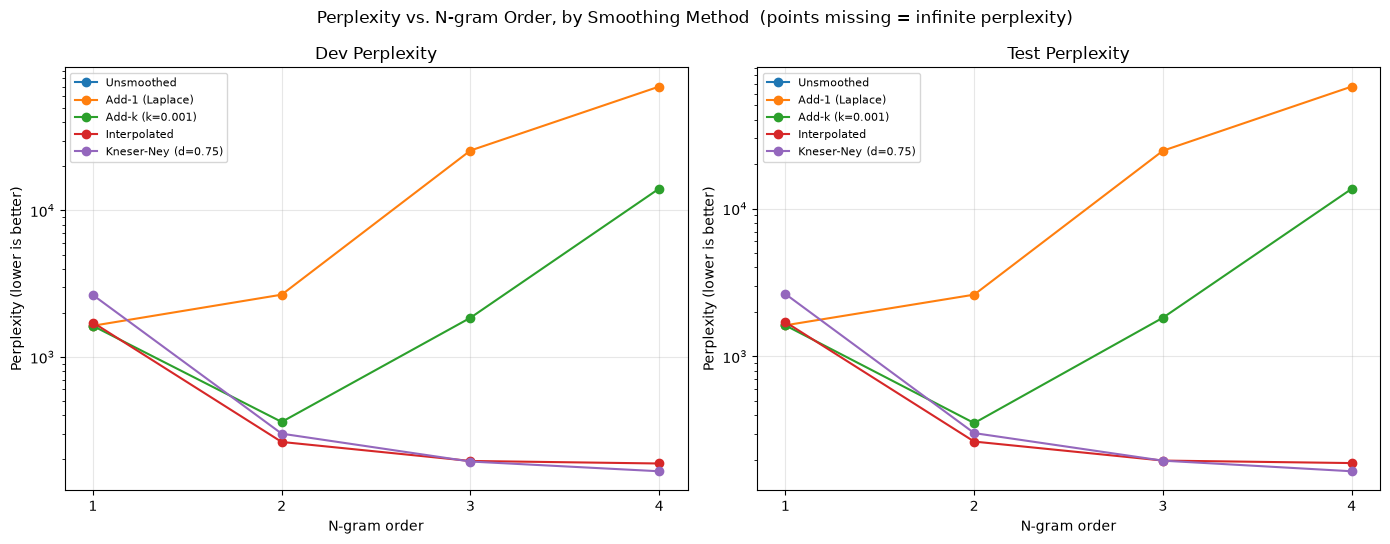

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for method in METHODS:
    sub = results_df[results_df["Method"] == method]
    finite = sub[np.isfinite(sub["Dev Perplexity"])]
    axes[0].plot(finite["Order (N)"], finite["Dev Perplexity"], marker="o", label=method)
    finite_t = sub[np.isfinite(sub["Test Perplexity"])]
    axes[1].plot(finite_t["Order (N)"], finite_t["Test Perplexity"], marker="o", label=method)

for ax, title in zip(axes, ["Dev Perplexity", "Test Perplexity"]):
    ax.set_xlabel("N-gram order")
    ax.set_ylabel("Perplexity (lower is better)")
    ax.set_title(title)
    ax.set_xticks([1, 2, 3, 4])
    ax.legend(fontsize=8)
    ax.set_yscale("log")
    ax.grid(alpha=0.3)

plt.suptitle("Perplexity vs. N-gram Order, by Smoothing Method  (points missing = infinite perplexity)")
plt.tight_layout()
plt.show()



## Section 13 — Discussion

Guidance for what to look for and write up, grounded in what each method is
mathematically built to do — fill this in with the *actual* numbers from your run:

- **Unsmoothed at $N\ge2$ will very likely show `inf`** on dev/test. This is not a
  bug: any single held-out n-gram never seen in training gets probability exactly
  $0$, which makes the whole sequence's probability $0$ and perplexity infinite.
  This is *the* textbook motivation for smoothing — a model this brittle is
  unusable on any text it wasn't trained on verbatim.
- **Add-1 tends to *worsen* as order increases**, or at least improve far less than
  the other methods. It divides a fixed unit of probability mass across the entire
  vocabulary $V$ for *every* context — with $V$ often in the tens of thousands and
  most higher-order contexts occurring only a handful of times, add-1 ends up
  massively over-smoothing, pulling probability away from genuinely informative
  higher-order counts. This is the classic, well-documented criticism of Laplace
  smoothing for NLP (Jurafsky & Martin, Ch. 3).
- **Add-$k$ with a small tuned $k$** should behave much better than Add-1, since a
  smaller pseudo-count disturbs the real counts far less while still guaranteeing
  no zero probabilities.
- **Interpolation** should track add-$k$ or beat it, since it lets each order fall
  back gracefully onto a strictly lower-order (and thus more reliably estimated)
  model, rather than a flat uniform distribution over all of $V$.
- **Kneser-Ney should be the strongest performer, especially at $N=3,4$** — this is
  the single most consistent empirical finding in the n-gram LM literature. Its
  continuation-count backoff means a word's fallback weight reflects how many
  *different* contexts it's genuinely used in, not just its raw frequency — a much
  better model of what's actually likely in a novel context than "spread mass
  uniformly" (Laplace) or "spread mass by raw unigram frequency" (interpolation's
  own base case).
- **Across all methods, perplexity should generally *decrease* as $N$ increases**
  (more context → better predictions) **up to a point** — watch for whether it
  starts increasing again at $N=4$ for the weaker methods, which would indicate
  data sparsity is starting to outweigh the extra context (very plausible on a
  ~1,000,000-sentence training set at the quadrigram level, where most 4-gram
  contexts are seen only once or twice).

**Report, concretely:**
1. The full dev/test table from Section 11.
2. The chosen $k$ (Section 10) and why the grid search landed there.
3. The chosen $\\lambda_1,\\dots,\\lambda_4$ and the trend across orders (do later
   orders trust their own MLE more or less than earlier orders? What does that
   imply about how much you can trust a quadrigram count versus a bigram count on
   this corpus?).
4. Which method wins at each order, and whether the *same* method wins at every
   order or the ranking changes with $N$.
